# Ridge feature experiments

Tune alpha on the two earlier folds, then test schools, malls, both, and strictly historical rental summaries. Amenity snapshots lack opening histories; results are associational and historically uncertain.

Run notebooks 06–10 in order. Existing notebooks 01–05 and processed datasets are read-only inputs. Results are written to `experiments/results/`. Scores use individual rents in SGD; tuning folds are July–December 2023 and January–June 2024. No final-block scores are used in model or feature selection.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "data/train.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from experiments import rental_experiments as exp


## Experiment configuration

Ridge tests alpha 10 and 100 on the original 35 features, then tests each feature group using the selected alpha. Numeric inputs use training-median imputation and scaling; categories use sparse, fold-fitted one-hot encoding with minimum frequency 10. Feature groups are schools (six columns), malls (three), both (nine), and past rental means/counts by town × flat type and property (four). Historical summaries exclude the current month for training rows and remain frozen at the training cutoff for evaluation rows.

The shared implementation and optional configuration arguments are in `experiments/rental_experiments.py`.

In [2]:
scores = exp.model_experiment("ridge")
display(scores)
display(scores.groupby(["group", "params"])[["RMSE", "MAE", "seconds"]].mean())

ridge keep_all block_recovery base {'alpha': 10} 2023_H2: RMSE=597.807; 1.2s


ridge keep_all block_recovery base {'alpha': 10} 2024_H1: RMSE=603.809; 1.5s


ridge keep_all block_recovery base {'alpha': 100} 2023_H2: RMSE=599.948; 1.2s


ridge keep_all block_recovery base {'alpha': 100} 2024_H1: RMSE=606.816; 1.6s


ridge keep_all block_recovery schools {'alpha': 10} 2023_H2: RMSE=597.799; 1.7s


ridge keep_all block_recovery schools {'alpha': 10} 2024_H1: RMSE=603.975; 1.7s


... (4 outputs left out)

ridge keep_all block_recovery history {'alpha': 10} 2023_H2: RMSE=599.960; 1.6s


ridge keep_all block_recovery history {'alpha': 10} 2024_H1: RMSE=608.035; 1.9s


,model,policy,imputation,group,params,fold,RMSE,MAE,bias_actual_minus_predicted,train_rows,evaluation_rows,seconds
0,ridge,keep_all,block_recovery,base,"{""alpha"": 10}",2023_H2,597.806985,461.813783,-72.694134,87937,17900,1.198122
1,ridge,keep_all,block_recovery,base,"{""alpha"": 10}",2024_H1,603.809265,439.507799,-300.321325,105837,18179,1.457534
2,ridge,keep_all,block_recovery,base,"{""alpha"": 100}",2023_H2,599.947656,463.013164,-74.865767,87937,17900,1.218384
3,ridge,keep_all,block_recovery,base,"{""alpha"": 100}",2024_H1,606.815959,439.223872,-301.506677,105837,18179,1.649509
4,ridge,keep_all,block_recovery,schools,"{""alpha"": 10}",2023_H2,597.798750,461.796314,-72.788387,87937,17900,1.712735
5,ridge,keep_all,block_recovery,schools,"{""alpha"": 10}",2024_H1,603.975229,439.636783,-300.475507,105837,18179,1.729523
6,ridge,keep_all,block_recovery,malls,"{""alpha"": 10}",2023_H2,597.808321,461.821222,-72.712880,87937,17900,1.319186
7,ridge,keep_all,block_recovery,malls,"{""alpha"": 10}",2024_H1,603.897463,439.617159,-300.394246,105837,18179,1.587283
8,ridge,keep_all,block_recovery,schools_malls,"{""alpha"": 10}",2023_H2,597.843034,461.807963,-72.910180,87937,17900,1.474092
9,ridge,keep_all,block_recovery,schools_malls,"{""alpha"": 10}",2024_H1,603.926695,439.585745,-300.336220,105837,18179,1.799858


RMSE         MAE   seconds
group         params                                          
base          {"alpha": 100}  603.381808  451.118518  1.433946
              {"alpha": 10}   600.808125  450.660791  1.327828
history       {"alpha": 10}   603.997707  450.772277  1.752263
malls         {"alpha": 10}   600.852892  450.719191  1.453235
schools       {"alpha": 10}   600.886989  450.716549  1.721129
schools_malls {"alpha": 10}   600.884865  450.696854  1.636975

In [3]:
import json
display(json.loads((exp.OUT / "ridge_selection.json").read_text()))

{'model': 'ridge',
 'params': {'alpha': 10},
 'group': 'base',
 'policy': 'keep_all',
 'imputation': 'block_recovery',
 'mean_RMSE': 600.8081251689713,
 'feature_selection_rule': 'Minimum earlier-fold mean RMSE; retain base if improvement <1 SGD.',
 'seed_policy': 'MLP uses predeclared seed 42; other seeds are stability diagnostics.'}

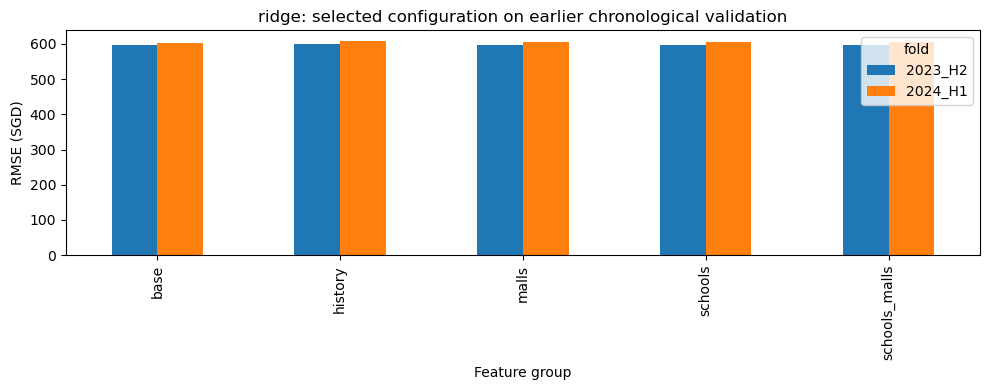

In [4]:
selected = json.loads((exp.OUT / "ridge_selection.json").read_text())
fixed = scores[scores.params.eq(json.dumps(selected["params"], sort_keys=True))]
summary = fixed.groupby(["group", "fold"]).RMSE.mean().unstack("fold")
summary.plot.bar(figsize=(10, 4))
plt.ylabel("RMSE (SGD)")
plt.xlabel("Feature group")
plt.title("ridge: selected configuration on earlier chronological validation")
plt.tight_layout()
plt.show()

## Interpretation

Read per-fold scores before interpreting the mean. A lower score does not establish causality. Explain temporal drift, duplicate uncertainty, snapshot limitations, and computational cost in the report. Hyperparameters and selections are saved alongside results.

References: [CatBoost fit API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit); [scikit-learn MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html).